In [5]:
from langgraph.graph import StateGraph, START, END

from state import UserProfile, REQUIRED_FIELDS
from agents.intake_agent import get_profile, load_language
from agents.eligibilty_agent import select_schemes
from agents.document_agent import build_document_checklist


# 1. The caste values your UserProfile accepts
CASTE_OPTIONS = ["OC", "BC", "SC", "ST", "EWS", "Minority"]


def clean_caste(value):
    """The voice agent gives free text (like "sc"). Turn it into one of the
    allowed values, or None."""

    if not value:
        return None

    value = str(value).strip()

    for option in CASTE_OPTIONS:
        if value.lower() == option.lower():
            return option

    return None


# 2. Intake node: voice agent fills the profile
def intake_node(state: UserProfile) -> UserProfile:
    """Takes the user details with the help of a Voice agent"""

    # get_profile() returns a dict, or None if the user quit before confirming
    profile_data = get_profile()

    if profile_data is None:
        print("Intake was not completed. The profile is unchanged.")
        return state

    # the language the user picked, so the next voice agents use the same one
    language, locale = load_language()

    return UserProfile(
        age=profile_data.get("age"),
        gender=profile_data.get("gender"),
        state=state.state,  # keeps "Andhra Pradesh"
        district=profile_data.get("district"),
        occupation=profile_data.get("occupation"),
        annual_income=profile_data.get("annual_income"),
        land_acres=profile_data.get("land_acres"),
        caste_category=clean_caste(profile_data.get("caste_category")),
        language=language,
        locale=locale,
    )


# 3. The profile details that go to the later agents (empty ones are skipped)
def profile_of(state: UserProfile) -> dict:
    profile = state.model_dump(
        include={
            "age", "gender", "state", "district", "occupation",
            "annual_income", "land_acres", "caste_category",
        }
    )

    return {key: value for key, value in profile.items() if value is not None}


# 4. Scheme selection node: takes the profile filled by the intake node,
#    compares it with the scheme documents and lets the user choose by voice
def scheme_selection_node(state: UserProfile) -> UserProfile:
    """Compares the profile from the intake node with all the schemes in the
    documents, tells the user the best ones by voice and saves the schemes
    the user chooses"""

    # same language the user chose in the intake node
    result = select_schemes(profile_of(state), state.language, state.locale)

    if result is None:
        print("Scheme selection was not completed. The state is unchanged.")
        return state

    # same state, with the new fields filled in
    return state.model_copy(
        update={
            "ranked_schemes": result["ranked_schemes"],
            "selected_schemes": result["selected_schemes"],
            "language": result["language"],
            "locale": result["locale"],
        }
    )


# 5. Document node: documents, dates and steps for the schemes the user chose,
#    told to the user by voice in the selected language
def document_node(state: UserProfile) -> UserProfile:
    """Builds the document checklist for the selected schemes"""

    result = build_document_checklist(
        profile_of(state),
        state.selected_schemes,
        state.language,
        state.locale,
    )

    return state.model_copy(
        update={
            "scheme_details": result["schemes"],
            "document_checklist": result["checklist"],
        }
    )


# 6. The graph
builder = StateGraph(UserProfile)

builder.add_node("intake", intake_node)
builder.add_node("scheme_selection", scheme_selection_node)
builder.add_node("document_checklist", document_node)

def after_intake(state: UserProfile) -> str:
    """Go on to scheme selection only if intake filled every required detail (age, gender, ...)"""

    missing = [f for f in REQUIRED_FIELDS if getattr(state, f) is None]

    if missing:
        print("Stopping, intake is missing:", missing)
        return END

    return "scheme_selection"


def after_selection(state: UserProfile) -> str:
    """Go on to the document checklist only if the user chose a scheme"""

    if not state.selected_schemes:
        print("Stopping, no scheme was selected.")
        return END

    return "document_checklist"


builder.add_edge(START, "intake")
builder.add_conditional_edges("intake", after_intake)
builder.add_conditional_edges("scheme_selection", after_selection)
builder.add_edge("document_checklist", END)

graph = builder.compile()


if __name__ == "__main__":
    result = graph.invoke(UserProfile())
    print(result)

ai: Hello! What is your age?
user: 30
ai: Thank you. Are you male or female?
user: male
ai: What is your occupation?
user: farmer
ai: Which district do you live in?
user: amalapuram
ai: What is your annual income in rupees?
user: 100000
ai: Here are your details: age 30, male, farmer, district Amalapuram, annual income 100000 rupees. Is this correct?
user: yes
ai: Thank you. How many acres of land do you own?

Final profile: {'age': 30, 'gender': 'male', 'occupation': 'farmer', 'district': 'amalapuram', 'annual_income': 100000, 'land_acres': None, 'caste_category': None}
Comparing your profile with all the schemes, please wait...
ai: Based on the uploaded documents, there is **one scheme** available for comparison. Here is the ranking of your profile against it.

---

**Rank 1. Annadata Sukhibhava AP**

- **Status:** Likely eligible

- **Why it matches (criteria you meet):**
  - **Residency:** You are from Andhra Pradesh. The document states: *"Residency: Must be a permanent resident o

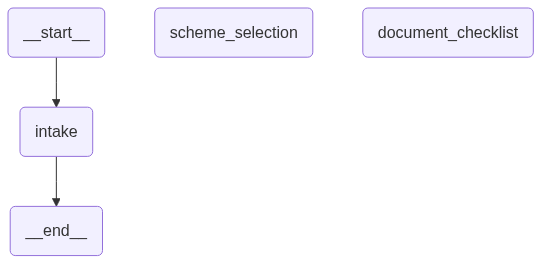

In [6]:
from IPython.display import Image
Image(graph.get_graph().draw_mermaid_png())